# IST curve smoothing and idealized target construction (delta arm)

Exploratory notebook for the delta-mode RNN experiment:

1. Load the `dyconex_260701_seq2seq` train/test targets and split them into
   per-variable IST curves (var 1 = `delta_A_norm`, var 2 = `delta_B_norm`).
2. Re-anchor curves that dip below 0 (mostly early noise/bias): discard the
   points before the dip, set the dip value as the new zero. Only genuinely
   faulty curves (deep dip, or too few points left) are dropped.
3. Fit each surviving curve with a monotone smooth function
   (Savitzky-Golay local cubic + isotonic monotonization, zero-centered);
   a global cubic fit is shown for comparison.
4. Failure reconstruction: curves shorter than the full test length are
   treated as failed (ambiguous cases count as failed for BOTH variables);
   the last observed value is set to exactly 1.0 and the censored tail is
   clamped at 1.0.
5. Diagnostics: increment distributions before/after smoothing.

The smoothing is used ONLY to build the delta targets; the raw values are
kept for reference. The baked dataset is produced by
`scripts/build_smooth_dataset.py` once this notebook is validated.


In [10]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from sklearn.isotonic import IsotonicRegression

# ---------------------------------------------------------------- config
DATA_DIR = Path("../data/input/dyconex_260701_seq2seq")
FULL_LEN = 200            # points per variable in a complete test
FAIL_VALUE = 1.0          # idealized failure level (normalized)
DROP_ANY_NEGATIVE = True  # drop curves with any raw value < 0
SG_POLYORDER = 3          # local cubic
SG_MAX_WINDOW = 21        # cap on the Savitzky-Golay window (odd)

# Okabe-Ito colorblind palette
CB = {
    "raw": "#999999", "sg": "#0072B2", "cubic": "#E69F00",
    "iso": "#009E73", "fail": "#D55E00", "drop": "#CC79A7",
}
plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
    "axes.titleweight": "bold", "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 11, "figure.dpi": 110,
})

VAL_CH, POS_CH, VAR_CH = 3, 1, 2
VAR_IDS = (1.0, 2.0)


## 1. Load data and extract per-variable curves


In [11]:
def load_curves(npz_path):
    """Return list of dicts: per sample, per variable -> (pos, val) observed."""
    d = np.load(npz_path)
    y = d["y"]
    curves = []
    for i in range(y.shape[0]):
        sample = {}
        for v in VAR_IDS:
            m = y[i, :, VAR_CH] == v
            pos = y[i, m, POS_CH]
            val = y[i, m, VAL_CH]
            ok = ~np.isnan(val)
            order = np.argsort(pos[ok])
            sample[v] = (pos[ok][order], val[ok][order])
        curves.append(sample)
    return curves

train_curves = load_curves(DATA_DIR / "train_data.npz")
test_curves = load_curves(DATA_DIR / "test_data.npz")
print(f"train samples: {len(train_curves)}, test samples: {len(test_curves)}")
for v in VAR_IDS:
    lens = np.array([len(c[v][1]) for c in train_curves])
    print(f"var {v:.0f}: len min/med/max = {lens.min()}/{int(np.median(lens))}/{lens.max()}, "
          f"short (<{FULL_LEN}): {(lens < FULL_LEN).sum()}")


train samples: 1311, test samples: 176
var 1: len min/med/max = 22/200/200, short (<200): 35
var 2: len min/med/max = 2/200/200, short (<200): 73


## 2. Curves dipping below 0: re-anchor instead of drop

Most negative excursions are small early dips (noise/bias), not faults:
median dip depth is ~-0.009 and ~94% of dips occur in the first 10% of the
curve. Instead of dropping these curves:

1. find the global minimum (the dip);
2. discard all points **before** the dip;
3. shift the curve up so the dip value becomes the new zero.

Only genuinely faulty curves are dropped:
- dip deeper than `DIP_DEPTH_MAX` (clear fault, e.g. the -0.78 outlier), or
- fewer than `MIN_LEN_AFTER_TRIM` points left after trimming.

Review the salvaged and dropped curves below.


In [12]:
DIP_DEPTH_MAX = 0.1       # normalized units; deeper dip -> faulty curve
MIN_LEN_AFTER_TRIM = 20   # too few points left after trimming -> drop


def reanchor(val):
    """Salvage a curve dipping below 0.

    Returns (val_proc, drop_reason):
    - val_proc: curve trimmed before the dip and shifted so the dip is the
      new zero (== input unchanged if the curve never goes negative);
    - drop_reason: None if kept, else a string explaining the drop.
    """
    if len(val) == 0:
        return val, "empty"
    imin = int(np.argmin(val))
    if val[imin] >= 0:
        return val, None
    if val[imin] < -DIP_DEPTH_MAX:
        return val, f"deep dip ({val[imin]:.3f})"
    val2 = val[imin:] - val[imin]
    if len(val2) < MIN_LEN_AFTER_TRIM:
        return val2, f"only {len(val2)} pts after trim"
    return val2, None


# apply to every curve; a SAMPLE is dropped if any of its variables is dropped
def process_split(curves):
    proc, drop = [], {}
    for i, c in enumerate(curves):
        sample, reasons = {}, {}
        for v in VAR_IDS:
            pos, val = c[v]
            vp, reason = reanchor(val)
            sample[v] = (pos, val, vp, reason)  # keep raw for review plots
            if reason:
                reasons[v] = reason
        proc.append(sample)
        if reasons:
            drop[i] = reasons
    return proc, drop

train_proc, train_drop = process_split(train_curves)
test_proc, test_drop = process_split(test_curves)
print(f"train: kept {len(train_curves) - len(train_drop)}/{len(train_curves)} "
      f"({100*(1 - len(train_drop)/len(train_curves)):.1f}%), dropped {len(train_drop)}")
print(f"test : kept {len(test_curves) - len(test_drop)}/{len(test_curves)} "
      f"({100*(1 - len(test_drop)/len(test_curves)):.1f}%), dropped {len(test_drop)}")
for i, r in list(train_drop.items())[:10]:
    print(f"  drop sample {i}: " + ", ".join(f"var{v:.0f}: {s}" for v, s in r.items()))

# how many curves were re-anchored?
n_reanch = sum(1 for c in train_proc for v in VAR_IDS
               if len(c[v][2]) != len(c[v][1]))
print(f"train curves re-anchored (trimmed+shifted): {n_reanch}")


train: kept 1304/1311 (99.5%), dropped 7
test : kept 175/176 (99.4%), dropped 1
  drop sample 1: var1: deep dip (-0.213), var2: deep dip (-0.208)
  drop sample 7: var1: only 8 pts after trim, var2: deep dip (-0.160)
  drop sample 21: var2: deep dip (-0.783)
  drop sample 58: var2: deep dip (-0.141)
  drop sample 546: var1: deep dip (-0.110)
  drop sample 1031: var2: deep dip (-0.473)
  drop sample 1290: var1: deep dip (-0.129)
train curves re-anchored (trimmed+shifted): 735


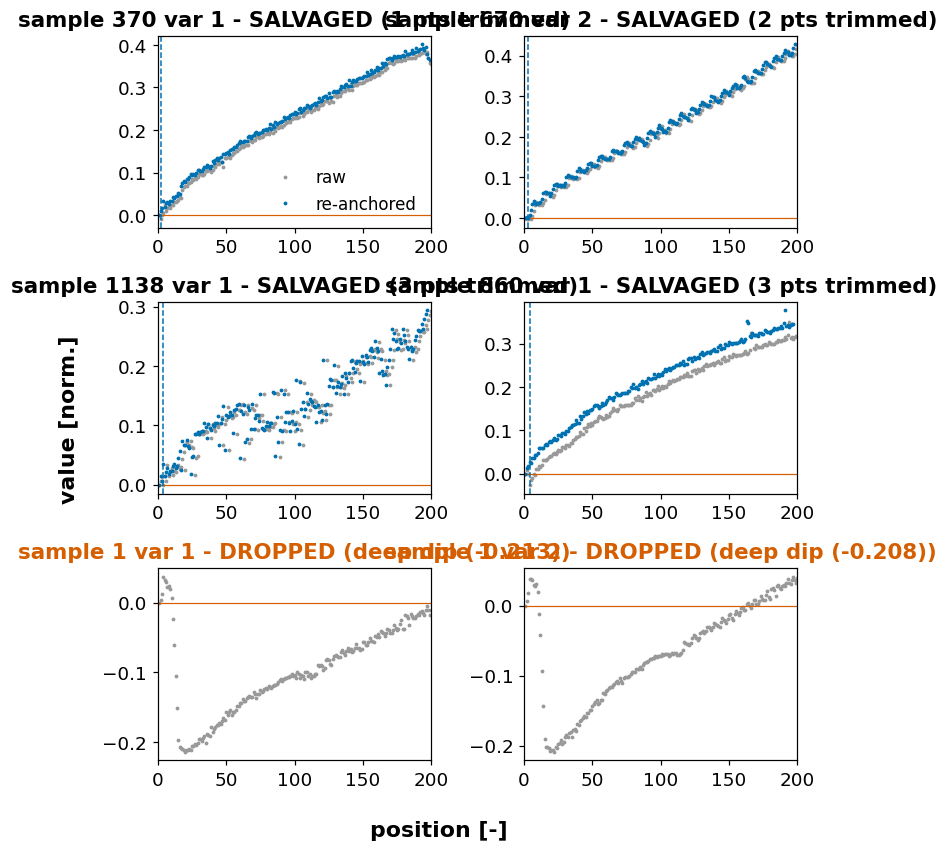

In [13]:
# review: re-anchored curves (top) and dropped curves (bottom)
reanch = [(i, v) for i, c in enumerate(train_proc) for v in VAR_IDS
          if i not in train_drop and len(c[v][2]) != len(c[v][1])]
rng = np.random.default_rng(0)
sel_r = rng.choice(len(reanch), size=min(4, len(reanch)), replace=False)
drops = [(i, v) for i, r in train_drop.items() for v in r]
sel_d = range(min(2, len(drops)))
panels = [("reanch", reanch[k]) for k in sel_r] + [("drop", drops[k]) for k in sel_d]

fig, axes = plt.subplots(3, 2, figsize=(7.2, 7.8))
for k, (kind, (i, v)) in enumerate(panels):
    pos, val, vp, reason = train_proc[i][v]
    ax = axes[k // 2, k % 2]
    ax.plot(pos, val, ".", ms=3, color=CB["raw"], label="raw")
    ax.axhline(0, color=CB["fail"], lw=0.8)
    if kind == "reanch":
        n_trim = len(val) - len(vp)
        ax.axvline(pos[n_trim], color=CB["sg"], lw=1, ls="--")
        ax.plot(np.arange(1, len(vp) + 1), vp, ".", ms=3, color=CB["sg"],
                label="re-anchored")
        ax.set_title(f"sample {i} var {v:.0f} - SALVAGED ({n_trim} pts trimmed)")
    else:
        ax.set_title(f"sample {i} var {v:.0f} - DROPPED ({reason})", color=CB["fail"])
    ax.set_xlim(0, FULL_LEN)
    if k == 0:
        ax.legend(frameon=False, loc="lower right")
for k in range(len(panels), 6):
    axes.flat[k].axis("off")
fig.supxlabel("position [-]", fontweight="bold")
fig.supylabel("value [norm.]", fontweight="bold")
fig.tight_layout()
plt.show()


## 3. Monotone smooth fit

Per curve, on the observed prefix only:
- Savitzky-Golay (local cubic, adaptive odd window) for smoothing;
- isotonic regression (increasing) on the smoothed values for monotonicity;
- zero-centering: subtract the fitted value at t=0, clip at 0.

A plain global cubic is computed alongside for comparison.


In [14]:
def sg_window(n, polyorder=SG_POLYORDER, cap=SG_MAX_WINDOW):
    w = min(cap, max(polyorder + 2, n // 8))
    w += 1 - w % 2  # odd
    return max(w, polyorder + 2 + (polyorder % 2 == 0))


def fit_sg_isotonic(val):
    """Monotone smooth, zero-centered fit of one (already re-anchored) curve."""
    n = len(val)
    w = min(sg_window(n), n if n % 2 else n - 1)
    sm = savgol_filter(val, w, SG_POLYORDER) if w > SG_POLYORDER and n >= 5 else val.copy()
    iso = IsotonicRegression(increasing=True, out_of_bounds="clip")
    sm = iso.fit_transform(np.arange(n), sm)
    sm = sm - sm[0]
    return np.clip(sm, 0.0, None)


def fit_cubic(val):
    n = len(val)
    if n < 5:
        return np.full(n, np.nan)
    c = np.polyfit(np.arange(n), val, 3)
    return np.polyval(c, np.arange(n))


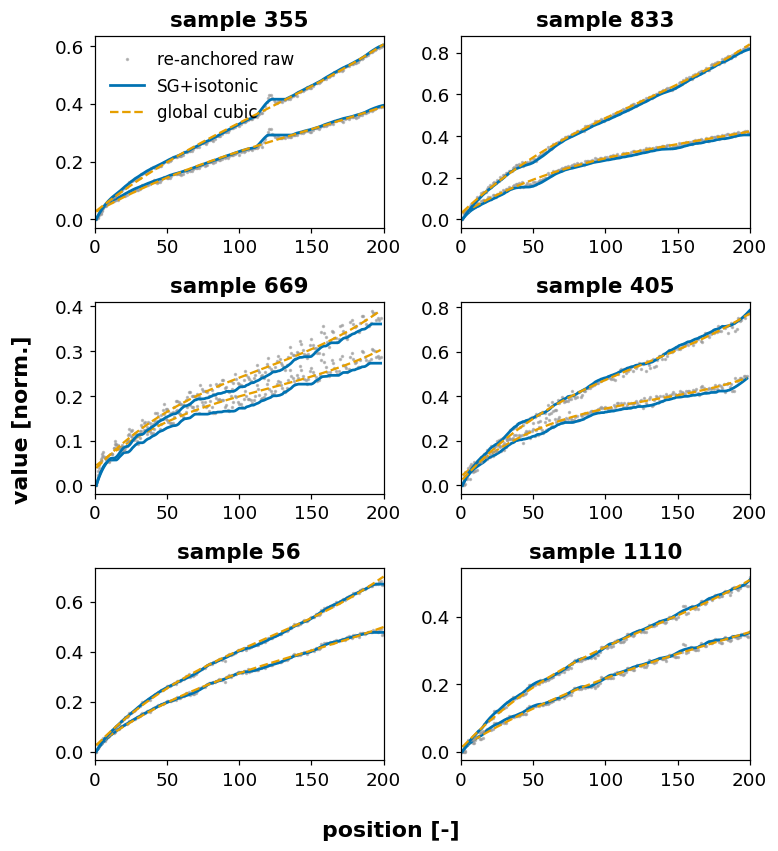

In [15]:
# comparison grid: raw vs SG-isotonic vs global cubic (on kept samples)
keep_idx = np.array([i for i in range(len(train_proc)) if i not in train_drop])
rng = np.random.default_rng(0)
show = rng.choice(keep_idx, size=6, replace=False)

fig, axes = plt.subplots(3, 2, figsize=(7.2, 7.8))
for k, i in enumerate(show):
    ax = axes[k // 2, k % 2]
    for v in VAR_IDS:
        pos, val, vp, reason = train_proc[i][v]
        if len(vp) < 5:
            continue
        lbl = (k == 0 and v == 1.0)
        ax.plot(np.arange(1, len(vp) + 1), vp, ".", ms=2.5, color=CB["raw"],
                alpha=0.6, label="re-anchored raw" if lbl else None)
        ax.plot(np.arange(1, len(vp) + 1), fit_sg_isotonic(vp), "-", lw=1.8,
                color=CB["sg"], label="SG+isotonic" if lbl else None)
        ax.plot(np.arange(1, len(vp) + 1), fit_cubic(vp), "--", lw=1.5,
                color=CB["cubic"], label="global cubic" if lbl else None)
    ax.set_title(f"sample {i}")
    ax.set_xlim(0, FULL_LEN)
axes[0, 0].legend(frameon=False)
fig.supxlabel("position [-]", fontweight="bold")
fig.supylabel("value [norm.]", fontweight="bold")
fig.tight_layout()
plt.show()


## 4. Failure reconstruction with a Bezier approach to 1.0

**Classification** (per variable, using the ORIGINAL observed curve):
- **failed**: short curve (< `FULL_LEN` points) ending high (last raw value
  >= `FAIL_TOL`), i.e. at the threshold within measurement uncertainty.
  Ambiguous case (BOTH variables short AND both ending low): both treated
  as failed.
- **interrupted**: short curve ending low while the partner variable is not
  clearly failed -> the test stopped for another reason. The curve keeps its
  smoothed values and its NaN tail untouched.
- **full**: full-length curve (test ended by duration, not failure).

**Reconstruction of failed curves**: the value 1.0 is reached AT the last
observed point (the actual failure instant); the last `BEZIER_K` observed
points are replaced by a cubic Bezier segment:
- P0 on the fitted curve at the junction;
- P1 set for C1 continuity (matches the local slope of the fit);
- P3 = (last point, 1.0);
- P2 controls the steepness of the finish (`BEZIER_END_FRAC`,
  `BEZIER_END_RISE`): the curve stays near its level, then turns sharply up.

After the last observed point: **NaN, exactly as in the raw data** - no
measurements are fabricated past failure.


In [16]:
FAIL_TOL = 0.98        # last raw value >= this -> failed (at threshold)
BEZIER_K = 10          # last k observed points replaced by the Bezier segment
BEZIER_END_FRAC = 0.85 # x-position of P2 in the segment (steepness handle)
BEZIER_END_RISE = 0.1  # fraction of the gap gained by P2 (small = steep finish)


def classify(entry, partner_entry):
    """failed / interrupted / full / empty, from ORIGINAL observed lengths."""
    n = len(entry[1])
    last = entry[1][-1] if n else np.nan
    n_p = len(partner_entry[1])
    last_p = partner_entry[1][-1] if n_p else np.nan
    if n == 0:
        return "empty"
    if n >= FULL_LEN:
        return "full"
    if last >= FAIL_TOL:
        return "failed"
    if n_p < FULL_LEN and last_p < FAIL_TOL:
        return "failed"  # ambiguous: both short, both low -> both failed
    return "interrupted"


def bezier_approach(sm, k=BEZIER_K, end_frac=BEZIER_END_FRAC,
                    end_rise=BEZIER_END_RISE):
    """Replace the last k points of the smooth fit by a cubic Bezier ending
    exactly at 1.0, C1-continuous at the junction."""
    n = len(sm)
    k = int(min(k, n))
    y0 = sm[-k]
    # local slope of the fit at the junction (per point)
    w = min(20, n - k)
    m = np.median(np.diff(sm[-k - w:-k])) if w >= 5 else 0.0
    P0 = np.array([0.0, y0])
    P1 = np.array([1.0 / 3.0, y0 + m * k / 3.0])
    P2 = np.array([end_frac, y0 + end_rise * (1.0 - y0)])
    P3 = np.array([1.0, 1.0])
    t = np.linspace(0.0, 1.0, k)
    B = ((1 - t) ** 3)[:, None] * P0 + (3 * (1 - t) ** 2 * t)[:, None] * P1 \
        + (3 * (1 - t) * t ** 2)[:, None] * P2 + (t ** 3)[:, None] * P3
    seg = np.clip(B[:, 1], 0.0, 1.0)
    out = sm.copy()
    out[-k:] = seg
    out = np.maximum.accumulate(out)  # enforce monotonicity (safety)
    return np.clip(out, 0.0, 1.0)


def idealize(entry, status, full_len=FULL_LEN):
    """Return (smooth_obs, full_curve) for one processed curve.

    full_curve: (full_len,) with NaN tail - positions after the last
    observation stay NaN, exactly as in the raw data.
    """
    pos, val_raw, val, _ = entry
    n = len(val)
    sm = fit_sg_isotonic(val) if n else np.array([])
    if status == "failed" and n:
        sm = bezier_approach(sm)
    full = np.full(full_len, np.nan)
    full[:n] = sm
    return sm, full


# classification inventory
counts = {s: {v: 0 for v in VAR_IDS} for s in ("failed", "interrupted", "full", "empty")}
status_map = {}
for i, c in enumerate(train_proc):
    if i in train_drop:
        continue
    for v in VAR_IDS:
        s = classify(c[v], c[2.0 if v == 1.0 else 1.0])
        counts[s][v] += 1
        status_map[(i, v)] = s
for s in counts:
    print(f"{s:12s}: var1={counts[s][1.0]:4d}  var2={counts[s][2.0]:4d}")


failed      : var1=  21  var2=  49
interrupted : var1=  11  var2=  21
full        : var1=1272  var2=1234
empty       : var1=   0  var2=   0


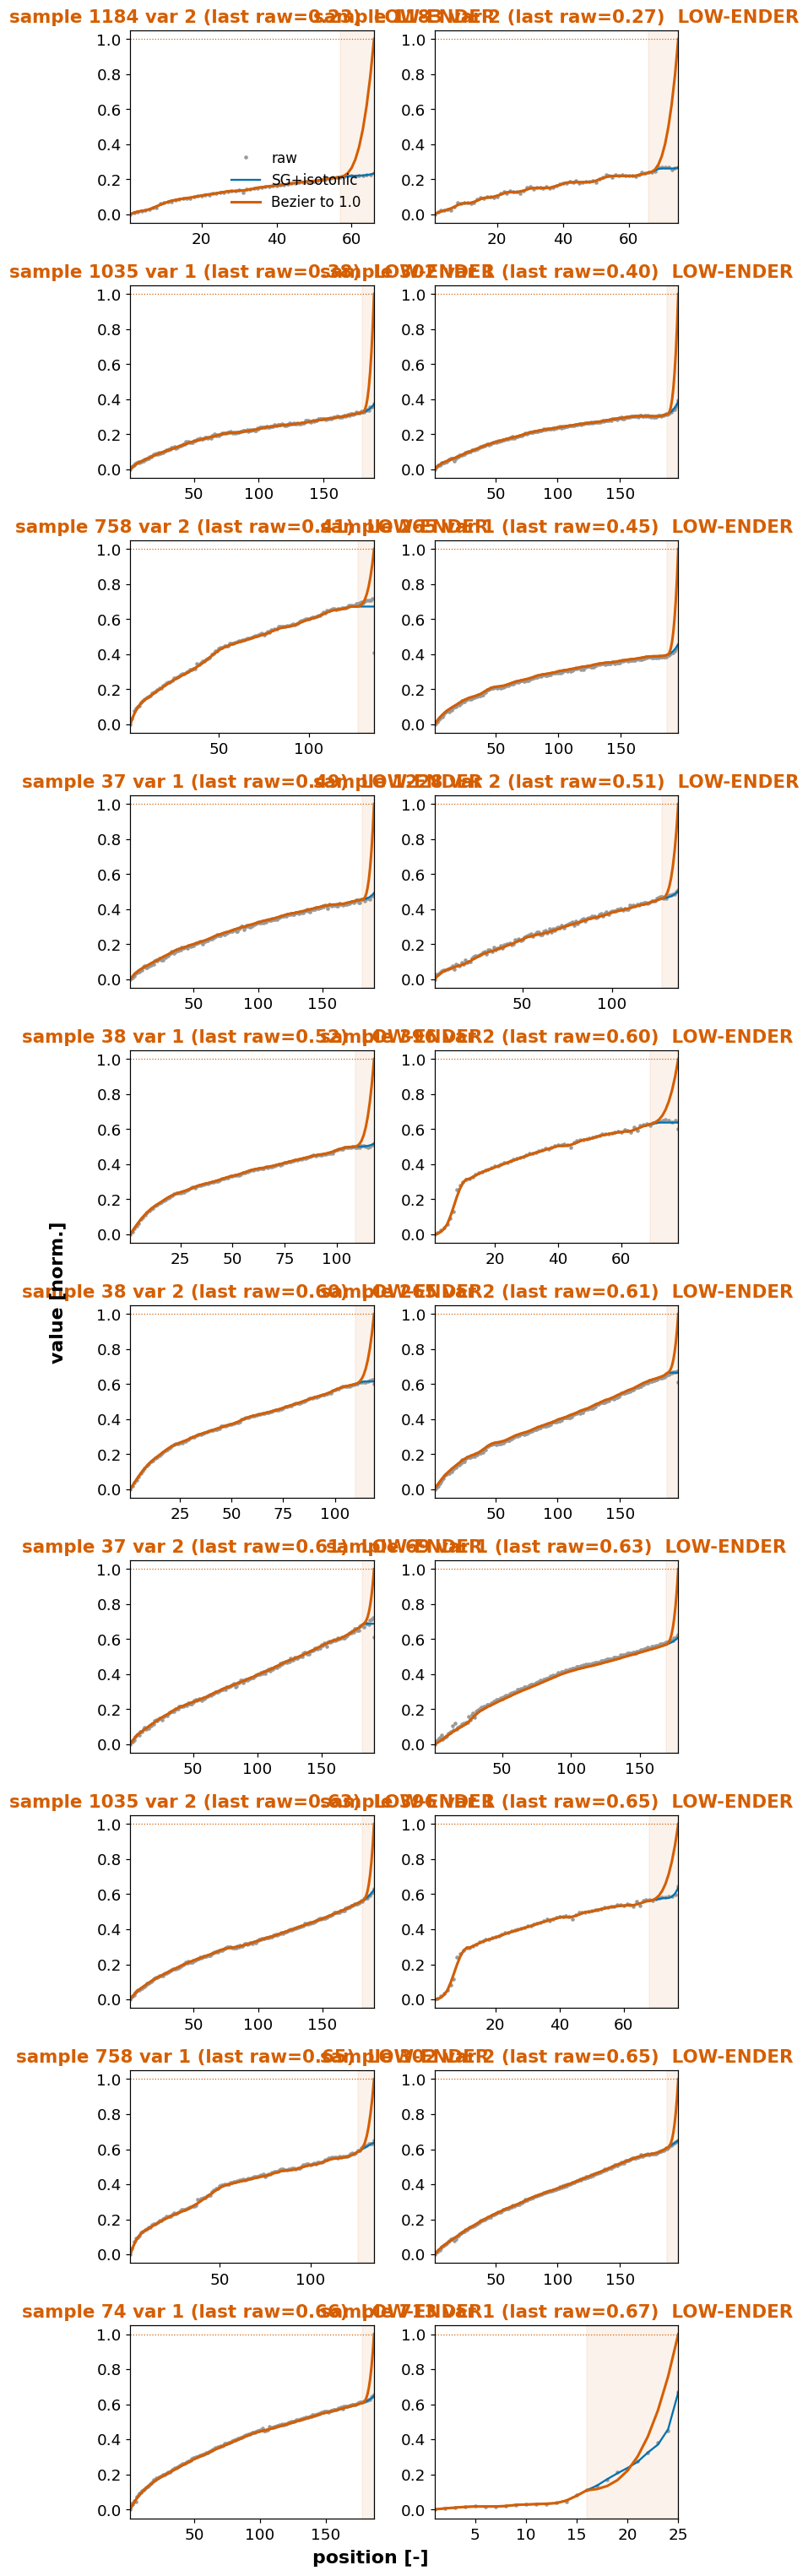

failed curves: 70; shaded band = Bezier window (last 10 pts)


In [29]:
# review panel: failed curves - zoom on the Bezier approach to 1.0
failed_list = [(i, v) for (i, v), s in status_map.items() if s == "failed"]
failed_list.sort(key=lambda t: train_proc[t[0]][t[1]][2][-1])  # lowest enders first
n_show = min(20, len(failed_list))
fig, axes = plt.subplots((n_show + 1) // 2, 2, figsize=(7.2, 2.8 * ((n_show + 1) // 2)))
axes = np.atleast_2d(axes)
ZOOM = 200
for k in range(n_show):
    i, v = failed_list[k]
    entry = train_proc[i][v]
    pos, val_raw, val, _ = entry
    sm, full = idealize(entry, "failed")
    n = len(val)
    ax = axes[k // 2, k % 2]
    lo = max(0, n - ZOOM)
    ax.plot(np.arange(lo + 1, n + 1), val[lo:], ".", ms=4, color=CB["raw"], label="raw")
    ax.plot(np.arange(lo + 1, n + 1), fit_sg_isotonic(val)[lo:], "-", lw=1.5,
            color=CB["sg"], label="SG+isotonic")
    ax.plot(np.arange(lo + 1, n + 1), sm[lo:], "-", lw=2.0,
            color=CB["fail"], label="Bezier to 1.0")
    ax.axhline(FAIL_VALUE, color=CB["fail"], lw=0.8, ls=":")
    ax.axvspan(n - BEZIER_K + 1, n, color=CB["fail"], alpha=0.08)
    low = val[-1] < 0.8
    ax.set_title(f"sample {i} var {v:.0f} (last raw={val[-1]:.2f})"
                 + ("  LOW-ENDER" if low else ""),
                 color=CB["fail"] if low else "black")
    ax.set_xlim(lo + 1, n)
    if k == 0:
        ax.legend(frameon=False, loc="lower right")
for k in range(n_show, axes.size):
    axes.flat[k].axis("off")
fig.supxlabel("position [-]", fontweight="bold")
fig.supylabel("value [norm.]", fontweight="bold")
fig.tight_layout()
plt.show()
print(f"failed curves: {len(failed_list)}; shaded band = Bezier window (last {BEZIER_K} pts)")


## 5. Increment distributions before / after smoothing

The money plot: raw first differences are noise-dominated; the idealized
increments should be tight, non-negative and sparse after failure.


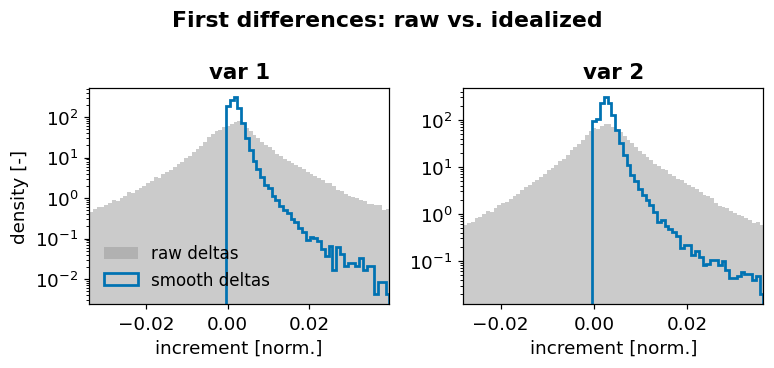

var 1: raw delta std=0.00986, smooth delta std=0.00202, smooth negative fraction=0.0000
var 2: raw delta std=0.00897, smooth delta std=0.00258, smooth negative fraction=0.0000


In [18]:
def collect_increments(proc, drop, smoothed):
    incs = {v: [] for v in VAR_IDS}
    for i, c in enumerate(proc):
        if i in drop:
            continue
        for v in VAR_IDS:
            val = c[v][2]  # re-anchored raw
            if len(val) < 5:
                continue
            x = fit_sg_isotonic(val) if smoothed else val - val[0]
            incs[v].append(np.diff(x))
    return {v: np.concatenate(lst) for v, lst in incs.items()}

raw_inc = collect_increments(train_proc, train_drop, smoothed=False)
sm_inc = collect_increments(train_proc, train_drop, smoothed=True)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
for ax, v in zip(axes, VAR_IDS):
    lo, hi = np.percentile(raw_inc[v], [0.5, 99.5])
    bins = np.linspace(lo, hi, 80)
    ax.hist(raw_inc[v], bins=bins, density=True, histtype="stepfilled",
            alpha=0.5, color=CB["raw"], label="raw deltas")
    ax.hist(sm_inc[v], bins=bins, density=True, histtype="step", lw=1.8,
            color=CB["sg"], label="smooth deltas")
    ax.set_yscale("log")
    ax.set_title(f"var {v:.0f}")
    ax.set_xlabel("increment [norm.]")
    ax.set_xlim(lo, hi)
axes[0].set_ylabel("density [-]")
axes[0].legend(frameon=False)
fig.suptitle("First differences: raw vs. idealized", fontweight="bold")
fig.tight_layout()
plt.show()

for v in VAR_IDS:
    print(f"var {v:.0f}: raw delta std={raw_inc[v].std():.5f}, "
          f"smooth delta std={sm_inc[v].std():.5f}, "
          f"smooth negative fraction={np.mean(sm_inc[v] < 0):.4f}")


## 6. Summary

Run the cells above, check:
- the re-anchored curves look physical (dip trimming removes only the early
  noise transient) and the few dropped curves are genuinely faulty;
- the SG+isotonic fits track the data without cubic-style edge artifacts;
- the LOW-ENDER failure reconstructions are acceptable.

If all looks good, the pipeline is baked into
`data/input/dyconex_260701_seq2seq_smooth/` by
`scripts/build_smooth_dataset.py`.
